# Дообучение поиска по вопросам об Отбасы банке

Сравнение GTE, BGE‑M3 и multilingual‑E5. Эти три модели заняли первые места по MRR@10 в предыдущем прогоне.
Для каждого завершённого прогона в этом файле сохранены результаты обучения, таблицы и графики. Завершено моделей: **3 из 3**.

Для каждой модели обучался небольшой остаточный слой, преобразующий эмбеддинги запросов и документов. Энкодеры заморожены. Все эмбеддинги получены локально на CPU с INT8‑квантизацией линейных слоёв и ограничением входа в 96 токенов. Исходные метрики пересчитаны на эмбеддингах этого прогона. Пакетирование при переиндексации может дать небольшие отличия от предыдущего файла.

**Настройки.** Ранг слоя 16 или 64, learning rate 0,0003 или 0,001, контрольные точки после 1, 3, 6 и 12 эпох. Для каждого энкодера проверены 16 конфигураций. Одна эпоха — 32 батча по 48 пар со случайным отбором между батчами. Выбор сделан по nDCG@10 на валидации, при равенстве — по MRR@10, числу эпох и размеру слоя.

**Валидация.** В пробном прогоне готовые перефразировки оказались слишком лёгкими: у исходной E5 nDCG@10 достигла 1,0. Для финального подбора использованы 36 отдельно сформулированных запросов по 18 отложенным семействам. Документы из тренировочных семейств добавлены в индекс валидации как нерелевантные кандидаты.

**Оценка.** После выбора конфигурации проведён косинусный поиск по всем 10 000 вопросам на тех же 16 контрольных запросах. Их семейства ответов исключены из обучения и валидации. Выбор трёх энкодеров основан на прежнем сравнении на этих сценариях. Оценка изменений относится к этому корпусу и выбранным запросам.

## Зависимости для повторного запуска

Сохранённые результаты видны при открытии. Для пересчёта положите Excel рядом с ноутбуком. Веса исходных моделей скачиваются при первом запуске.

In [ ]:
%pip install numpy pandas openpyxl matplotlib torch "transformers>=4.55,<5" "sentence-transformers>=5.1,<6" sentencepiece

## Контрольные вопросы и разбиение

Семейства образованы по нормализованному тексту ответа с заменой чисел. Точное совпадение ответа задаёт положительную пару при обучении. На итоговом тесте релевантность задаётся отдельными правилами для каждого сценария.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

XLSX = Path("Отбасы_банк_10000_вопросов_и_ответов.xlsx")
df = pd.read_excel(XLSX, sheet_name="Вопросы и ответы")
assert len(df) == 10000
questions = df["Вопрос"].astype(str).str.strip().tolist()


# Правила размечают строки, которые отвечают на контрольный вопрос с учётом его условий.
def relevant_rows(frame):
    q = frame["Вопрос"].str.casefold()
    a = frame["Ответ"].str.casefold()
    ref = frame["Статья или строка"].str.casefold()

    def has(series, fragment):
        return series.str.contains(fragment.casefold(), regex=False, na=False).to_numpy()

    return np.array([
        has(q, "сейчас владею долей") & has(a, "доля 25% в единственном жилье"),
        has(q, "сейчас владею долей") & has(a, "доля 50% в единственном жилье"),
        has(q, "продал свою квартиру") & has(q, "прошло два года") & has(a, "квартира, проданная в этот период, учитывается"),
        has(q, "зарегистрирован в алматы два года.") & has(a, "такой срок недостаточен"),
        has(a, "не позднее пятнадцати рабочих дней со дня подачи заявления"),
        has(ref, "строка 9") & has(a, "скачать документ с причиной отказа"),
        has(a, "выезд на постоянное место жительства в другой населенный пункт является основанием для снятия"),
        has(q, "умер супруг") & has(a, "очередность сохраняется"),
        has(a, "семьи с ребенком с инвалидностью отдельную дополнительную комнату"),
        has(a, "коммунальное жилье для этой категории предоставляет и распределяет акимат"),
        has(a, "размер сертификата и перечень категорий получателей определяет маслихат"),
        has(a, "не менее 20%") & has(a, "детей-сирот и детей"),
        has(q, "алименты на ребенка") & has(a, "такая выплата сама по себе не входит"),
        has(a, "списки состоящих на учете нуждающихся") & has(a, "ежемесячно"),
        has(a, "государственная регистрация такого договора не требуется"),
        has(ref, "строка 177") & has(a, "само по себе не ведет к снятию с учета"),
    ])


import re

SPLIT_SEED = 73

def make_split(frame, gold):
    """Group related answer templates and reserve control scenarios before tuning."""
    answers = frame["Ответ"].astype(str).map(lambda t: re.sub(r"\s+", " ", t.casefold()).strip())
    families = answers.map(lambda t: re.sub(r"\d+(?:[.,]\d+)?", "#", t))
    family_by_row = pd.factorize(families, sort=True)[0]
    answer_by_row = pd.factorize(answers, sort=True)[0]

    held_out_families = np.unique(family_by_row[gold.any(axis=0)])
    allowed = ~np.isin(family_by_row, held_out_families)
    candidates = np.unique(family_by_row[allowed])
    rng = np.random.default_rng(SPLIT_SEED)
    order = rng.permutation(candidates)
    validation_families = order[:max(1, round(len(order) * 0.22))]
    validation_mask = allowed & np.isin(family_by_row, validation_families)
    training_mask = allowed & ~validation_mask

    def rows_by_answer(mask):
        return {
            int(ans): np.flatnonzero(mask & (answer_by_row == ans))
            for ans in np.unique(answer_by_row[mask])
        }

    train_groups = {ans: rows for ans, rows in rows_by_answer(training_mask).items() if len(rows) >= 2}
    val_groups = {ans: rows for ans, rows in rows_by_answer(validation_mask).items() if len(rows) >= 3}
    train_aux = []
    for rows in train_groups.values():
        train_aux.extend(rng.choice(rows, size=min(len(rows), 24), replace=False))
    val_queries = []
    for rows in val_groups.values():
        val_queries.extend(rng.choice(rows, size=min(4, len(rows) - 1), replace=False))
    val_queries = np.sort(val_queries).astype(np.int64)
    train_aux = np.sort(train_aux).astype(np.int64)
    aux_ids = np.union1d(val_queries, train_aux)
    # Validation can retrieve only from its own families; training and test families are excluded.
    val_index = np.setdiff1d(np.flatnonzero(validation_mask), val_queries)
    assert len(train_groups) >= 5 and len(val_groups) >= 3
    assert not set(family_by_row[training_mask]) & set(family_by_row[validation_mask])
    assert not set(family_by_row[training_mask | validation_mask]) & set(held_out_families)
    assert not set(val_queries) & set(val_index)
    assert np.isin(answer_by_row[val_queries], answer_by_row[val_index]).all()
    return dict(
        aux_ids=aux_ids, train_aux=train_aux, val_queries=val_queries, val_index=val_index,
        answer_by_row=answer_by_row, family_by_row=family_by_row,
        train_mask=training_mask, val_mask=validation_mask, test_family_mask=~allowed,
    )


CONTROL_QUERIES = [
    [
        "Доля 25%",
        "У меня четверть в единственной квартире. Может ли такая доля помешать постановке на жилищный учёт?"
    ],
    [
        "Доля 50%",
        "У меня половина в единственной квартире. Будет ли это основанием для отказа в постановке на жилищный учёт?"
    ],
    [
        "Продажа квартиры",
        "Продал квартиру в другом регионе два года назад. Учитывается ли она, если сейчас хочу встать на жилищный учёт?"
    ],
    [
        "Срок регистрации",
        "Живу в Алматы и зарегистрирован там всего второй год. Хватит ли этого для постановки на жилищный учёт, если я не сирота?"
    ],
    [
        "Срок ответа",
        "Сколько рабочих дней у банка на решение по заявлению о постановке в жилищную очередь?"
    ],
    [
        "Отказ в инвентаризации",
        "В проверке данных для жилищной очереди мне отказали. Откуда скачать документ с объяснением?"
    ],
    [
        "Смена места жительства",
        "Уехал в другой населённый пункт на постоянное жительство. Могут ли меня исключить из списка нуждающихся?"
    ],
    [
        "Смерть супруга",
        "После смерти мужа сохранится ли за мной очередность, если мы стояли на учёте вместе и я всё ещё нуждаюсь в жилье?"
    ],
    [
        "Инвалидность ребёнка",
        "Положена ли семье ещё одна отдельная комната при предоставлении жилья, если у ребёнка инвалидность?"
    ],
    [
        "Аварийное жильё",
        "Мой единственный дом официально признан аварийным. Кто решает, предоставить ли нам коммунальную квартиру?"
    ],
    [
        "Жилищный сертификат",
        "Кто утверждает сумму жилищного сертификата и перечень тех, кто может его получить?"
    ],
    [
        "Квота для сирот",
        "Какая минимальная доля жилья при распределении предусмотрена для сирот и детей без попечения родителей?"
    ],
    [
        "Алименты",
        "При расчёте дохода для жилищной господдержки посчитают ли алименты на ребёнка как заработок?"
    ],
    [
        "Публикация списков",
        "С какой периодичностью банк публикует списки состоящих на жилищном учёте?"
    ],
    [
        "Договор найма",
        "Надо ли оформлять государственную регистрацию письменного договора найма квартиры из государственного фонда?"
    ],
    [
        "Доход выше порога",
        "Заработок оказался выше допустимого в одном отборе. Означает ли это снятие с жилищного учёта?"
    ]
]
VALIDATION_QUERIES = [
    [
        1,
        "Я отправила данные для проверки очередников. В каком разделе кабинета можно увидеть решение по заявке?",
        "Где на портале посмотреть, закончилась ли проверка сведений обо мне как об очереднике?"
    ],
    [
        13,
        "Мне уже выдали государственную квартиру в пользование. Примут ли ещё раз заявление на жилищный учёт?",
        "Можно ли снова встать в очередь, пока пользуюсь квартирой из жилфонда государства?"
    ],
    [
        14,
        "В документах для жилищной очереди указали неверные данные. Может ли банк из-за этого отклонить заявление?",
        "В анкете для постановки на учёт обнаружили недостоверную информацию. Это основание для отказа?"
    ],
    [
        19,
        "Стою на жилищном учёте в Казахстане, но получила ВНЖ за границей. Могу ли лишиться очереди?",
        "Оформил право на постоянное проживание за рубежом. Что будет с моим учётом на жильё в Казахстане?"
    ],
    [
        20,
        "Из списка нуждающихся меня исключили. Обязаны ли прислать письменное объяснение и когда?",
        "Через сколько сообщат причину исключения из жилищной очереди, и будет ли это изложено письменно?"
    ],
    [
        21,
        "Я на двадцать пятой неделе беременности. Учитывается ли это при определении площади жилья для семьи?",
        "Беременность на сроке 24 недели. Будет ли это учитываться, когда определяют размер предоставляемой квартиры?"
    ],
    [
        27,
        "У меня вторая группа инвалидности и я стою в очереди. Относится ли мой случай к общей квоте в половину жилья?",
        "Мы многодетная семья на учёте. Входим ли мы в группу получателей, которым совокупно выделяют как минимум половину жилья?"
    ],
    [
        29,
        "Если жильё предоставляют по льготной ипотечной мере, где искать правила расчёта площади на семью?",
        "Каким документом определяют норму площади для жилья в рамках мер из подпункта 3 пункта 1 статьи 10-8?"
    ],
    [
        31,
        "Квартиру у частного собственника снял акимат, а заселяют меня. С кем я должен подписать договор?",
        "Кто будет второй стороной письменного поднайма, если акимат нанял квартиру на частном рынке?"
    ],
    [
        50,
        "Ребёнку с инвалидностью исполнилось 18. Потеряет ли семья жилищную очередь из-за одного только возраста?",
        "Подросток с инвалидностью достиг совершеннолетия. Может ли это само по себе снять нас с учёта нуждающихся?"
    ],
    [
        56,
        "При распределении господдержки важен только год, когда я попала в очередь, или учитывают ещё заработок?",
        "Я очень давно в очереди. Влияют ли доходы на порядок предоставления жилищной поддержки?"
    ],
    [
        63,
        "Заявитель я, но муж работает. Учитывают ли его зарплату при оценке дохода для господдержки?",
        "При расчёте дохода для жилищной помощи банк посмотрит заработок жены, если документы подал я?"
    ],
    [
        86,
        "У меня беременность ровно двадцать одна неделя. Достаточно ли такого срока, чтобы учли её при расчёте площади?",
        "Учитывают ли беременность при подборе размера жилья, если сейчас прошло ровно 22 недели?"
    ],
    [
        96,
        "Сообщение с результатом распределения не пришло. В каком кабинете можно проверить, предварительно дали ли мне квартиру?",
        "Если телефон молчит после отбора на жильё, можно ли увидеть предварительное распределение на площадке банка?"
    ],
    [
        105,
        "При заселении из государственного фонда допустимо ли поселить брата и сестру в одну комнату?",
        "Могут ли дать сыну и дочери общую спальню при распределении, если закон учитывает пол жильцов?"
    ],
    [
        109,
        "Суд отменил усыновление, ребёнок вернулся в учреждение. Какая дата будет стоять у него в жилищной очереди?",
        "Ребёнок снова в интернате после отмены усыновления. В очередь восстановят со старой или с новой датой?"
    ],
    [
        113,
        "На какой площадке узнаю, когда в моём регионе откроют заявки на квартиры с кредитом?",
        "Где следить за объявлениями о старте приёма на кредитное жильё Отбасы банка?"
    ],
    [
        116,
        "Сколько времени даётся попечителю на постановку ребёнка на жилищный учёт после передачи под попечительство?",
        "Ребёнка-сироту приняли в организацию образования. Какой срок у представителя для подачи на жилищный учёт?"
    ]
]
gold = relevant_rows(df)
split = make_split(df, gold)
test_questions = [question for _, question in CONTROL_QUERIES]

def split_overview(split):
    entries = [
        ("Обучение", "train_mask", len(split["train_aux"]), "В пределах train"),
        ("Валидация", "val_mask", sum(len(queries) for _, *queries in VALIDATION_QUERIES), int((~split["test_family_mask"]).sum())),
        ("Контрольный тест", "test_family_mask", len(CONTROL_QUERIES), len(df)),
    ]
    return pd.DataFrame([
        {"Часть": caption, "Семейств ответов": len(set(split["family_by_row"][split[key]])),
         "Строк в семействах": int(split[key].sum()), "Запросов": n_queries,
         "Документов для поиска": pool}
        for caption, key, n_queries, pool in entries
    ])

display(split_overview(split))

Часть,Семейств ответов,Строк в семействах,Запросов,Документов для поиска
Обучение,63,4277,1527,В пределах train
Валидация,18,2130,36,6407
Контрольный тест,18,3593,16,10000


## Анализ данных

Единица корпуса — строка с вопросом, готовым ответом, темой и ссылкой на источник. База сформирована из приложенных материалов. У 10 000 разных формулировок 126 разных текстов ответа; многие строки представляют варианты одной ситуации. Пять самых частых тем занимают 74,27% корпуса. Поэтому результаты на этом наборе прежде всего показывают качество по представленным сценариям, а доли тем отражают сборку корпуса.

Показатель,Значение
Строк,10000
Уникальных формулировок,10000
Уникальных текстов ответов,126
Тем,17
Пустых ячеек,0
"Медиана длины вопроса, слов",23
"95-й перцентиль длины, слов",33


Источник,Строк,Доля
Закон,9377,93.77%
Таблица,603,6.03%
Таблица и закон,20,0.20%


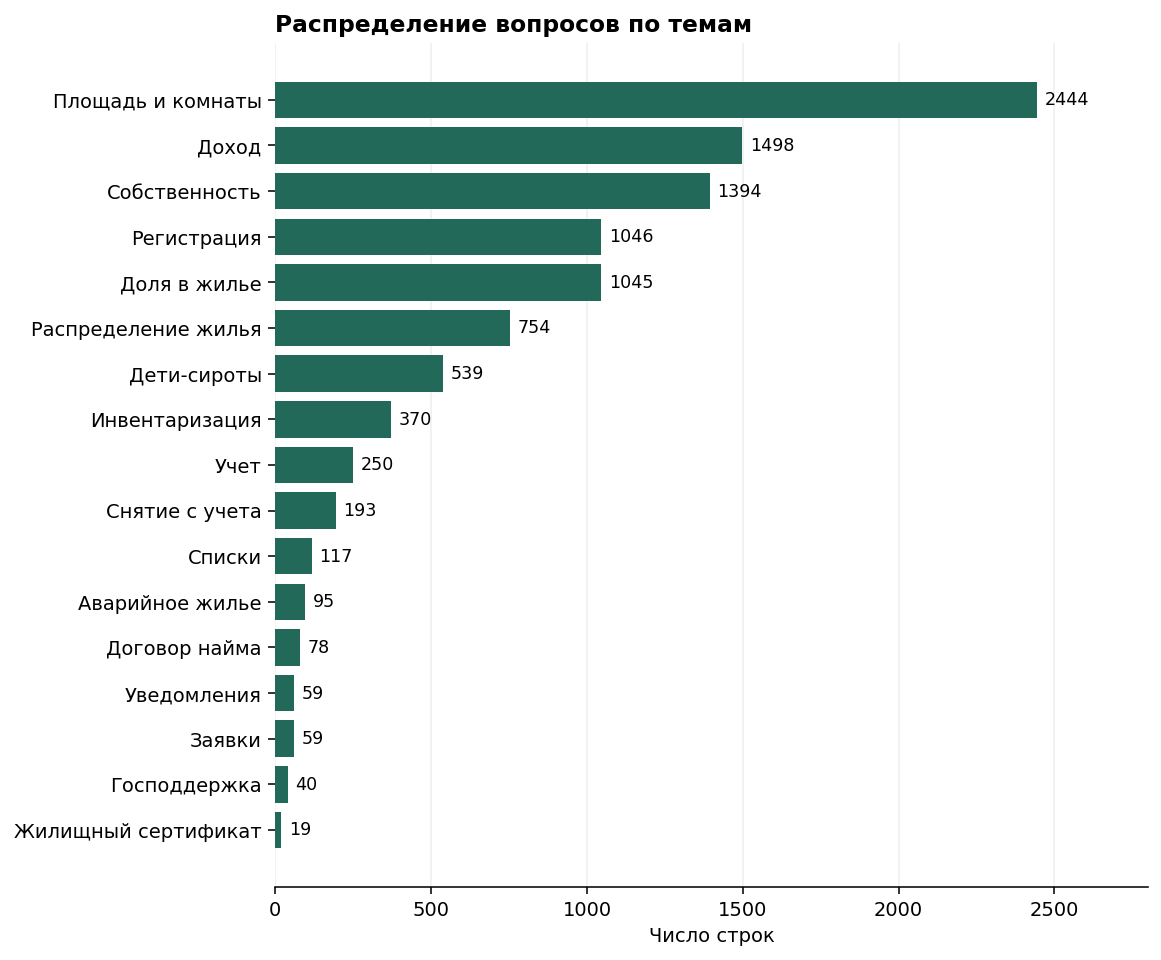

In [23]:
from matplotlib import pyplot as plt

length = df["Вопрос"].str.split().str.len()
profil = pd.DataFrame({
    "Показатель": ["Строк", "Уникальных формулировок", "Уникальных текстов ответов", "Тем",
                   "Пустых ячеек", "Медиана длины вопроса, слов", "95-й перцентиль длины, слов"],
    "Значение": [len(df), df["Вопрос"].nunique(), df["Ответ"].nunique(), df["Тема"].nunique(),
                 int(df.isna().sum().sum()), int(length.median()), int(length.quantile(.95))],
})
topic_counts = df["Тема"].value_counts().rename_axis("Тема").reset_index(name="Строк")
source_counts = df["Источник"].value_counts().rename_axis("Источник").reset_index(name="Строк")
source_counts["Доля"] = source_counts["Строк"] / len(df)

def draw_topics(topic_counts, limit=None):
    subset = topic_counts.head(limit) if limit else topic_counts
    fig, ax = plt.subplots(figsize=(8.4, 0.34 * len(subset) + 1.2))
    bars = ax.barh(subset["Тема"], subset["Строк"], color="#226959")
    ax.bar_label(bars, padding=4, fmt="%.0f", fontsize=9)
    ax.set_xlim(0, 2800)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=.20)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_xlabel("Число строк")
    ax.set_title("Распределение вопросов по темам", loc="left", fontweight="bold")
    fig.tight_layout()
    return fig

display(profil, source_counts.assign(Доля=source_counts["Доля"].map("{:.2%}".format)))
draw_topics(topic_counts)
plt.show()

## Эмбеддинги замороженных энкодеров

Запустите определения ниже, затем нужные ячейки моделей. Для E5 префиксы запроса и документа заданы отдельно. Кэш позволяет возобновлять прогон после остановки.

In [ ]:
from pathlib import Path
from time import perf_counter

import numpy as np
import torch
from sentence_transformers import SentenceTransformer


MODELS = {
    'GTE': ('Alibaba-NLP/gte-multilingual-base', '', '',
            '9bbca17d9273fd0d03d5725c7a4b0f6b45142062', '40ced75c3017eb27626c9d4ea981bde21a2662f4'),
    'BGE-M3': ('BAAI/bge-m3', '', '', None, None),
    'multilingual-E5': ('intfloat/multilingual-e5-small', 'passage: ', 'query: ', None, None),
}

def load_encoder(name):
    repo, dp, qp, revision, code_revision = MODELS[name]
    model = SentenceTransformer(repo, device='cpu', revision=revision, trust_remote_code=bool(code_revision),
                                model_kwargs={'code_revision': code_revision} if code_revision else {})
    model.max_seq_length = 96
    torch.backends.quantized.engine = 'fbgemm'
    torch.ao.quantization.quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8, inplace=True)

    def encode(texts, prefix):
        return model.encode([prefix + text for text in texts], batch_size=48, normalize_embeddings=True,
                            show_progress_bar=False, convert_to_numpy=True).astype(np.float32)
    return encode, dp, qp


def encode_corpus(name, questions, test_questions, e5_row_ids, cache, threads=1):
    torch.set_num_threads(threads)
    cache = Path(cache)
    cache.mkdir(exist_ok=True, parents=True)
    final = cache / f'{name}.npz'
    if final.exists():
        return final
    started = perf_counter()
    encode, dp, qp = load_encoder(name)

    order = np.argsort(np.asarray([len(q) for q in questions]), kind='stable')[::-1]
    parts = []
    for start in range(0, len(order), 480):
        ids = order[start:start+480]
        chunk = cache / f'{name}-{start:05d}.npy'
        if not chunk.exists():
            block = encode([questions[i] for i in ids], dp)
            tmp = chunk.with_suffix('.tmp.npy')
            np.save(tmp, block, allow_pickle=False)
            tmp.replace(chunk)
        parts.append(np.load(chunk, allow_pickle=False))
        print(f'{name}: {min(start+480,len(order))}/{len(order)}', flush=True)
    docs = np.concatenate(parts)[np.argsort(order)]
    tests = encode(test_questions, qp)
    e5_row_ids = np.asarray(e5_row_ids, dtype=np.int64)
    if dp != qp:
        aux = encode([questions[i] for i in e5_row_ids], qp)
    else:
        aux = docs[e5_row_ids]
    assert docs.shape[0] == len(questions)
    assert all(np.isfinite(a).all() for a in (docs, tests, aux))
    temp = final.with_suffix('.tmp.npz')
    np.savez(temp, docs=docs, tests=tests, aux=aux, aux_ids=e5_row_ids, seconds=perf_counter()-started)
    temp.replace(final)
    print(f'{name}: saved {docs.shape}', flush=True)
    return final

## Обучение проекции и расчёт метрик

Положительные пары — разные строки с одинаковым ответом. Остальные ответы в батче используются как отрицательные примеры. Проекция начинается с тождественного преобразования, затем обновляется контрастивной функцией потерь. Для оценки каждый преобразованный вектор нормируется и сравнивается косинусным сходством.

In [ ]:
from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

TRAIN_SEED = 74
CHECKPOINTS = (1, 3, 6, 12)
RANKS = (16, 64)
LEARNING_RATES = (3e-4, 1e-3)
STEPS_PER_EPOCH = 32
TEMPERATURE = 0.07

class ResidualProjection(nn.Module):
    def __init__(self, dimension, rank):
        super().__init__()
        self.input_scale = dimension ** 0.5
        self.down = nn.Linear(dimension, rank, bias=False)
        self.up = nn.Linear(rank, dimension, bias=False)
        nn.init.zeros_(self.up.weight)

    def forward(self, vectors):
        delta = self.up(F.gelu(self.down(vectors * self.input_scale))) / self.input_scale
        return F.normalize(vectors + delta, dim=1)


def ranking_metrics(scores, relevance):
    """Binary relevance, averaged across query-level metrics."""
    assert scores.shape == relevance.shape and relevance.any(axis=1).all()
    top = np.argsort(-scores, axis=1, kind="stable")[:, :10]
    hits = np.take_along_axis(relevance, top, axis=1)
    rank = np.where(hits.any(axis=1), hits.argmax(axis=1) + 1, 0)
    reciprocal = np.divide(1, rank, out=np.zeros(len(rank), dtype=float), where=rank > 0)
    discount = 1 / np.log2(np.arange(2, 12))
    ideal = discount.cumsum()[np.minimum(relevance.sum(axis=1), 10) - 1]
    each = np.column_stack([hits[:, :3].any(axis=1), hits[:, :5].mean(axis=1),
                            reciprocal, (hits * discount).sum(axis=1) / ideal])
    return dict(zip(("Hit@3", "Precision@5", "MRR@10", "nDCG@10"), each.mean(axis=0))), each


def normalize_np(values):
    values = np.asarray(values, dtype=np.float32)
    return values / np.maximum(np.linalg.norm(values, axis=1, keepdims=True), 1e-12)


def train_and_score(name, data, split, test_relevance, dev_vectors, dev_labels):
    """Tune on validation query families, then score the frozen test queries."""
    started = perf_counter()
    docs = torch.from_numpy(normalize_np(data["docs"]))
    test_queries = torch.from_numpy(normalize_np(data["tests"]))
    aux = torch.from_numpy(normalize_np(data["aux"]))
    aux_ids = np.asarray(data["aux_ids"])
    assert np.array_equal(aux_ids, split["aux_ids"])
    labels = split["answer_by_row"]
    train_aux = split["train_aux"]
    val_index = np.flatnonzero(~split["test_family_mask"])
    assert set(dev_labels) == set(labels[split["val_mask"]])
    assert not set(dev_labels) & set(labels[split["train_mask"]])
    vq = torch.from_numpy(normalize_np(dev_vectors))
    vd = docs[val_index]
    val_gold = np.asarray(dev_labels)[:, None] == labels[val_index][None, :]
    groups = np.unique(labels[train_aux])
    train_positions = {g: train_aux[labels[train_aux] == g] for g in groups}
    train_docs = {g: np.flatnonzero(split["train_mask"] & (labels == g)) for g in groups}
    val_before, _ = ranking_metrics((vq @ vd.T).numpy(), val_gold)
    test_before, query_before = ranking_metrics((test_queries @ docs.T).numpy(), test_relevance)

    history = []
    best = None
    selected = None
    for rank, lr in product(RANKS, LEARNING_RATES):
        torch.manual_seed(TRAIN_SEED)
        rng = np.random.default_rng(TRAIN_SEED)
        model = ResidualProjection(docs.shape[1], rank)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.001)
        for epoch in range(1, max(CHECKPOINTS) + 1):
            cumulative_loss = 0.0
            model.train()
            for _ in range(STEPS_PER_EPOCH):
                chosen = rng.choice(groups, size=min(24, len(groups)), replace=False)
                batch_query = []
                batch_doc = []
                for group in chosen:
                    qids = rng.choice(train_positions[group], size=2, replace=False)
                    for qid in qids:
                        positives = train_docs[group]
                        did = rng.choice(positives[positives != qid])
                        batch_query.append(qid)
                        batch_doc.append(did)
                qids = np.asarray(batch_query)
                dids = np.asarray(batch_doc)
                q = model(aux[np.searchsorted(aux_ids, qids)])
                d = model(docs[dids])
                logits = (q @ d.T) / TEMPERATURE
                positive = torch.from_numpy(labels[qids, None] == labels[dids][None, :])
                match_logits = logits.masked_fill(~positive, float("-inf"))
                # Supervised multi-positive contrastive loss, symmetrized by direction.
                q_loss = (logits.logsumexp(1) - match_logits.logsumexp(1)).mean()
                d_loss = (logits.logsumexp(0) - match_logits.logsumexp(0)).mean()
                loss = (q_loss + d_loss) / 2
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                cumulative_loss += loss.item()
            if epoch in CHECKPOINTS:
                model.eval()
                with torch.inference_mode():
                    val_scores = (model(vq) @ model(vd).T).numpy()
                validation, _ = ranking_metrics(val_scores, val_gold)
                item = {"Модель": name, "Ранг слоя": rank, "Learning rate": lr, "Эпохи": epoch,
                        "Train loss": cumulative_loss / STEPS_PER_EPOCH, **validation}
                history.append(item)
                objective = (validation["nDCG@10"], validation["MRR@10"], -epoch, -rank)
                if best is None or objective > best:
                    best = objective
                    selected = (item, {key: value.detach().clone() for key, value in model.state_dict().items()})

    config, weights = selected
    tuned = ResidualProjection(docs.shape[1], config["Ранг слоя"])
    tuned.load_state_dict(weights)
    tuned.eval()
    with torch.inference_mode():
        test_scores = (tuned(test_queries) @ tuned(docs).T).numpy()
    assert np.isfinite(test_scores).all() and np.abs(test_scores).max() <= 1.0001
    test_after, query_after = ranking_metrics(test_scores, test_relevance)
    results = {"Модель": name, "До": test_before, "После": test_after, "Валидация до": val_before,
               "Выбранная настройка": config, "Секунд обучения и оценки": perf_counter() - started,
               "По запросам до": query_before.tolist(), "По запросам после": query_after.tolist()}
    return results, pd.DataFrame(history), weights


train_results, train_histories, trained_weights = [], [], {}

torch.set_num_threads(1)

### GTE

In [11]:
name = 'GTE'
cache_path = encode_corpus(name, questions, test_questions, split["aux_ids"], "tuning_cache", threads=1)
torch.set_num_threads(1)
encode, _, prefix = load_encoder(name)
dev_texts = [query for _, *queries in VALIDATION_QUERIES for query in queries]
dev_labels = np.array([label for label, *queries in VALIDATION_QUERIES for _ in queries])
dev_vectors = encode(dev_texts, prefix)
del encode
with np.load(cache_path, allow_pickle=False) as data:
    result, history, weights = train_and_score(name, data, split, gold, dev_vectors, dev_labels)
train_results = [r for r in train_results if r["Модель"] != name] + [result]
train_histories = [h for h in train_histories if h.iloc[0]["Модель"] != name] + [history]
trained_weights[name] = weights
print(result["Выбранная настройка"])

GTE: эмбеддинги для 10 000 вопросов готовы. Проверено 16 настроек.
Выбрано: 6 эпох, ранг 16, lr=0.001.


### BGE-M3

In [13]:
name = 'BGE-M3'
cache_path = encode_corpus(name, questions, test_questions, split["aux_ids"], "tuning_cache", threads=2)
torch.set_num_threads(1)
encode, _, prefix = load_encoder(name)
dev_texts = [query for _, *queries in VALIDATION_QUERIES for query in queries]
dev_labels = np.array([label for label, *queries in VALIDATION_QUERIES for _ in queries])
dev_vectors = encode(dev_texts, prefix)
del encode
with np.load(cache_path, allow_pickle=False) as data:
    result, history, weights = train_and_score(name, data, split, gold, dev_vectors, dev_labels)
train_results = [r for r in train_results if r["Модель"] != name] + [result]
train_histories = [h for h in train_histories if h.iloc[0]["Модель"] != name] + [history]
trained_weights[name] = weights
print(result["Выбранная настройка"])

BGE-M3: эмбеддинги для 10 000 вопросов готовы. Проверено 16 настроек.
Выбрано: 3 эпох, ранг 64, lr=0.001.


### multilingual-E5

In [15]:
name = 'multilingual-E5'
cache_path = encode_corpus(name, questions, test_questions, split["aux_ids"], "tuning_cache", threads=1)
torch.set_num_threads(1)
encode, _, prefix = load_encoder(name)
dev_texts = [query for _, *queries in VALIDATION_QUERIES for query in queries]
dev_labels = np.array([label for label, *queries in VALIDATION_QUERIES for _ in queries])
dev_vectors = encode(dev_texts, prefix)
del encode
with np.load(cache_path, allow_pickle=False) as data:
    result, history, weights = train_and_score(name, data, split, gold, dev_vectors, dev_labels)
train_results = [r for r in train_results if r["Модель"] != name] + [result]
train_histories = [h for h in train_histories if h.iloc[0]["Модель"] != name] + [history]
trained_weights[name] = weights
print(result["Выбранная настройка"])

multilingual-E5: эмбеддинги для 10 000 вопросов готовы. Проверено 16 настроек.
Выбрано: 1 эпох, ранг 16, lr=0.0003.


## Результаты на 16 контрольных запросах

Hit@3 измеряет долю запросов с подходящим результатом в тройке. Precision@5 измеряет долю подходящих строк в пятёрке. MRR@10 учитывает место первого подходящего результата. nDCG@10 учитывает позиции всех подходящих строк в десятке. Разница выражена в процентных пунктах на шкале 0–100%.

Интервалы рассчитаны парным бутстрэпом по 16 запросам, 10 000 перевыборок. Они показывают неопределённость изменения на небольшом наборе сценариев.

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

METRIC_NAMES = ("Hit@3", "Precision@5", "MRR@10", "nDCG@10")

def make_report(results, history):
    rows = []
    choices = []
    rng = np.random.default_rng(75)
    for result in results:
        name = result["Модель"]
        before = np.asarray(result["По запросам до"])
        after = np.asarray(result["По запросам после"])
        differences = after - before
        sample_idx = rng.integers(0, len(differences), size=(10000, len(differences)))
        low, high = np.quantile(differences[sample_idx].mean(axis=1), [0.025, 0.975], axis=0)
        for i, metric in enumerate(METRIC_NAMES):
            rows.append({
                "Модель": name, "Метрика": metric, "До": result["До"][metric], "После": result["После"][metric],
                "Δ, п.п.": 100 * differences[:, i].mean(),
                "95% интервал Δ, п.п.": f"[{100 * low[i]:+.2f}; {100 * high[i]:+.2f}]",
            })
        selected = result["Выбранная настройка"]
        choices.append({
            "Модель": name, "Эпохи": selected["Эпохи"], "Ранг слоя": selected["Ранг слоя"],
            "Learning rate": selected["Learning rate"],
            "Валидация nDCG@10 до": result["Валидация до"]["nDCG@10"],
            "Валидация nDCG@10 после": selected["nDCG@10"],
            "Секунд обучения и оценки": result["Секунд обучения и оценки"],
        })
    return pd.DataFrame(rows), pd.DataFrame(choices), pd.concat(history, ignore_index=True)


def plot_test_comparison(table):
    names = table["Модель"].drop_duplicates().tolist()
    x = np.arange(len(names))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
    for ax, metric in zip(axes.flat, METRIC_NAMES):
        view = table.loc[table["Метрика"] == metric].set_index("Модель").reindex(names)
        b1 = ax.bar(x - 0.17, view["До"], 0.32, label="Исходные эмбеддинги", color="#70a8b8")
        b2 = ax.bar(x + 0.17, view["После"], 0.32, label="После обучения слоя", color="#d08223")
        ax.bar_label(b1, labels=[f"{v:.1%}" for v in view["До"]], padding=2, fontsize=8)
        ax.bar_label(b2, labels=[f"{v:.1%}" for v in view["После"]], padding=2, fontsize=8)
        ax.set_xticks(x, labels=names)
        ax.set_ylim(0, 1.05)
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(axis="y", alpha=0.23)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_title(metric, loc="left", fontweight="bold")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2)
    fig.suptitle("Косинусный поиск до и после обучения", x=0.06, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    return fig


def plot_tuning_surface(results, history):
    names = [result["Модель"] for result in results]
    fig, axes = plt.subplots(1, len(names), figsize=(13.5, 4.4), squeeze=False, sharey=True)
    curves = history[["Ранг слоя", "Learning rate"]].drop_duplicates().sort_values(["Ранг слоя", "Learning rate"])
    colors = ["#176b87", "#b75e22", "#566d2e", "#713f72"]
    val_scores = [*history["nDCG@10"], *(r["Валидация до"]["nDCG@10"] for r in results)]
    span = max(val_scores) - min(val_scores)
    for ax, result in zip(axes[0], results):
        metric = result["Валидация до"]["nDCG@10"]
        ax.axhline(metric, ls="--", lw=1.3, color="#697781", label="Исходная модель")
        view = history.loc[history["Модель"] == result["Модель"]]
        for color, (rank, lr) in zip(colors, curves.itertuples(index=False, name=None)):
            trial = view.loc[(view["Ранг слоя"] == rank) & (view["Learning rate"] == lr)].sort_values("Эпохи")
            ax.plot(trial["Эпохи"], trial["nDCG@10"], "o-", color=color, label=f"r={rank}, lr={lr:g}")
        selected = result["Выбранная настройка"]
        ax.scatter([selected["Эпохи"]], [selected["nDCG@10"]], marker="*", s=180,
                   color="#ffd54a", edgecolor="#303840", zorder=10, label="Выбранная настройка")
        ax.set_title(result["Модель"])
        ax.set_xlabel("Эпохи")
        ax.set_xticks(sorted(view["Эпохи"].unique()))
        ax.set_ylim(max(0, min(val_scores) - 0.12 * max(span, 0.04)),
                    min(1.01, max(val_scores) + 0.12 * max(span, 0.04)))
        ax.grid(alpha=0.22)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0, 0].set_ylabel("nDCG@10 на валидации")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=3, frameon=False)
    fig.suptitle("Подбор ранга, скорости обучения и числа эпох", x=0.04, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.79))
    return fig



def pretty_comparison(comparison):
    formatted = comparison.copy()
    for column in ("До", "После"):
        formatted[column] = formatted[column].map("{:.2%}".format)
    formatted["Δ, п.п."] = formatted["Δ, п.п."].map("{:+.2f}".format)
    return formatted

def pretty_choice(choice):
    formatted = choice.copy()
    for column in ("Валидация nDCG@10 до", "Валидация nDCG@10 после"):
        formatted[column] = formatted[column].map("{:.4f}".format)
    formatted["Секунд обучения и оценки"] = formatted["Секунд обучения и оценки"].round(2)
    return formatted

def pretty_history(history):
    formatted = history.copy()
    for column in ("Hit@3", "Precision@5", "MRR@10", "nDCG@10", "Train loss"):
        formatted[column] = formatted[column].round(4)
    return formatted

comparison, selected, tuning_history = make_report(train_results, train_histories)
display(pretty_comparison(comparison))

Модель,Метрика,До,После,"Δ, п.п.","95% интервал Δ, п.п."
GTE,Hit@3,87.50%,75.00%,-12.50,[-31.25; +0.00]
GTE,Precision@5,68.75%,72.50%,+3.75,[-5.00; +16.25]
GTE,MRR@10,76.04%,73.29%,-2.75,[-7.74; +0.00]
GTE,nDCG@10,66.87%,72.82%,+5.95,[-2.24; +17.64]
BGE-M3,Hit@3,75.00%,81.25%,+6.25,[+0.00; +18.75]
BGE-M3,Precision@5,73.75%,80.00%,+6.25,[+0.00; +17.50]
BGE-M3,MRR@10,76.56%,81.25%,+4.69,[+0.00; +14.06]
BGE-M3,nDCG@10,74.28%,79.42%,+5.14,[+0.00; +14.64]
multilingual-E5,Hit@3,81.25%,81.25%,+0.00,[+0.00; +0.00]
multilingual-E5,Precision@5,65.00%,65.00%,+0.00,[-3.75; +3.75]


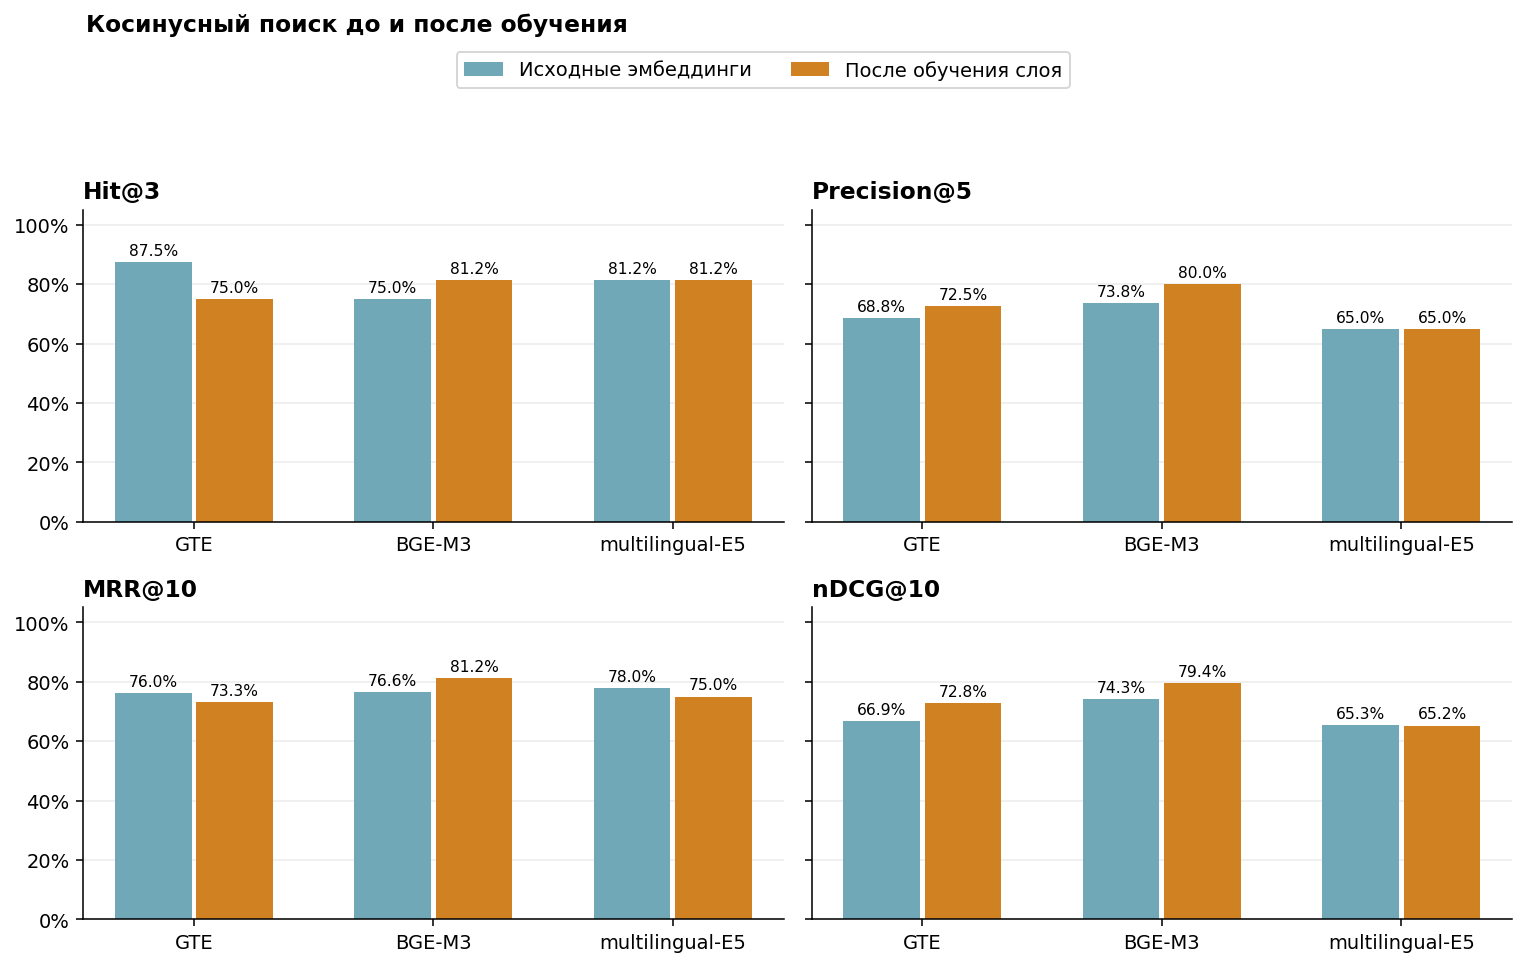

In [18]:
plot_test_comparison(comparison)
plt.show()

## Подбор гиперпараметров на валидации

Модель,Эпохи,Ранг слоя,Learning rate,Валидация nDCG@10 до,Валидация nDCG@10 после,Секунд обучения и оценки
GTE,6,16,0.0010,0.6911,0.6921,12.51
BGE-M3,3,64,0.0010,0.7936,0.8219,11.04
multilingual-E5,1,16,0.0003,0.7181,0.7277,10.59


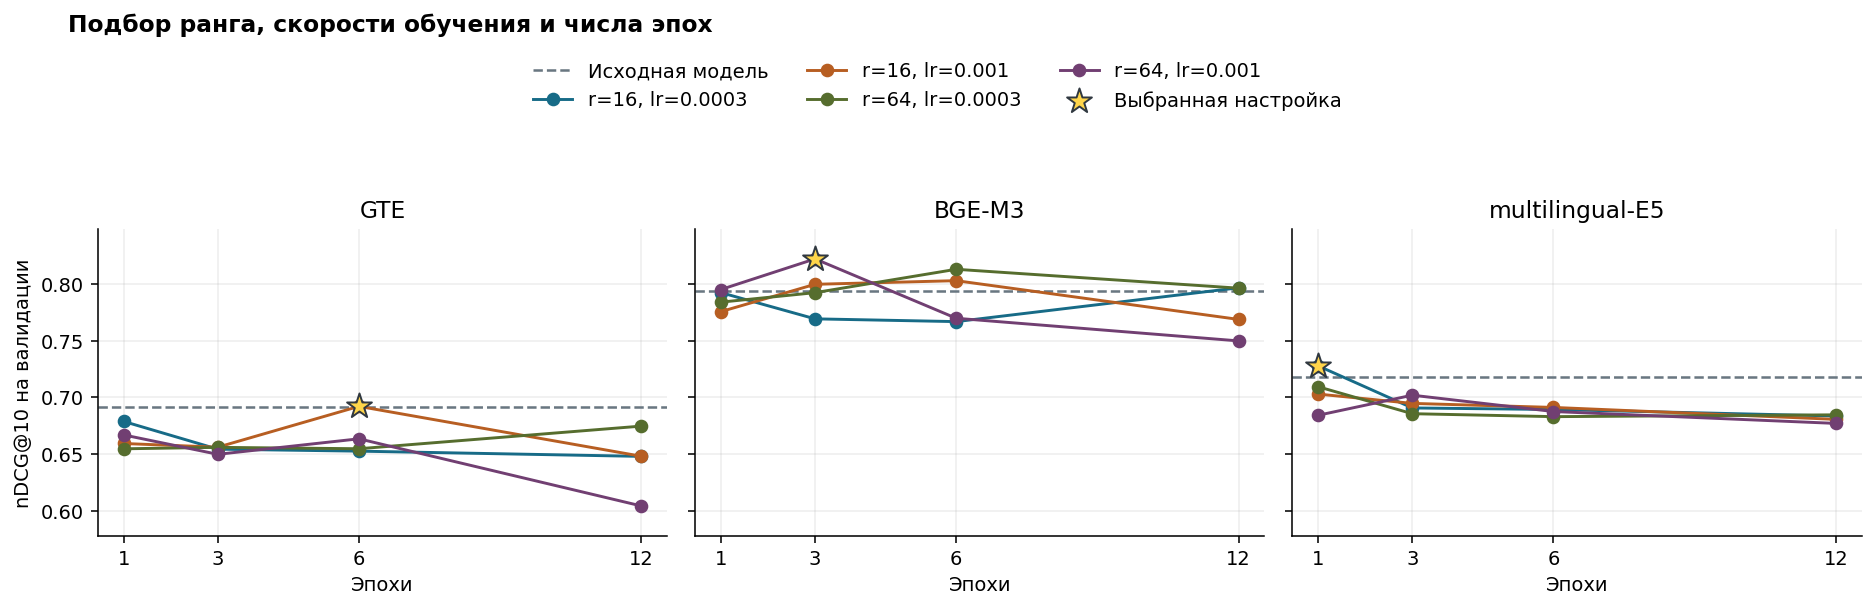

In [20]:
display(pretty_choice(selected))
plot_tuning_surface(train_results, tuning_history)
plt.show()

In [21]:
display(pretty_history(tuning_history))

Модель,Ранг слоя,Learning rate,Эпохи,Train loss,Hit@3,Precision@5,MRR@10,nDCG@10
GTE,16,0.0003,1,0.3963,0.7222,0.6778,0.7072,0.6788
GTE,16,0.0003,3,0.0329,0.6667,0.6556,0.6745,0.6544
GTE,16,0.0003,6,0.0244,0.6944,0.6556,0.6769,0.6526
GTE,16,0.0003,12,0.0141,0.7500,0.6611,0.6917,0.6480
GTE,16,0.0010,1,0.1864,0.7222,0.6611,0.7051,0.6594
GTE,16,0.0010,3,0.0219,0.6667,0.6556,0.6667,0.6561
GTE,16,0.0010,6,0.0094,0.7222,0.7000,0.7181,0.6921
GTE,16,0.0010,12,0.0054,0.7222,0.6667,0.7106,0.6481
GTE,64,0.0003,1,0.2638,0.6944,0.6611,0.6856,0.6547
GTE,64,0.0003,3,0.0257,0.6944,0.6667,0.6769,0.6560


Для повторного использования выбранный слой доступен в словаре trained_weights. Он загружается в ResidualProjection с рангом из итоговой таблицы. Перед косинусным сравнением примените выбранный слой к эмбеддингам документов и запросов одной модели.

## Почему метрики изменились

**BGE‑M3.** По запросу о продаже квартиры подходящий ответ поднялся с 4-го места на 1-е. Число релевантных строк в топ‑5 выросло с 1 до 5. По регистрации в топ‑5 стало на одну подходящую строку больше. Эти изменения объясняют прирост Hit@3 и Precision@5. По доле 50% позиция улучшилась с 41-й до 15-й и осталась за пределами топ‑10.

**GTE.** По отказу в инвентаризации первый подходящий ответ сохранил 1-е место, а число релевантных строк в пятёрке выросло с 1 до 5. По сроку регистрации подходящая строка опустилась с 3-го места на 4-е, по квоте для сирот — со 2-го на 7-е. Первые изменения улучшают качество списка, а последние снижают Hit@3 и MRR@10.

**multilingual‑E5.** По отказу в инвентаризации релевантный ответ опустился с 1-го места на 2-е. По продаже квартиры он поднялся с 7-го на 6-е. MRR сильнее реагирует на переход с первого места на второе, поэтому небольшое улучшение в нижней части списка его почти не компенсировало.

Проекционный слой обучался сближать вопросы с одинаковым ответом. Он меняет относительные расстояния между запросом и кандидатами. Это помогает одним группам и может сблизить соседние ситуации с разными условиями. Аудит показывает конкретные перестановки в выдаче. Precision@5 считает строки, поэтому несколько перефразировок одного ответа могут повысить эту метрику. Причину различий между архитектурами этот эксперимент отдельно не проверял. По nDCG@10 у всех трёх моделей 95%-й бутстрэп-интервал изменения включает ноль. Набор из 16 запросов даёт предварительную оценку.

In [26]:
audit_rows = [
  {
    "Модель": "GTE",
    "Сценарий": "Доля 25%",
    "Первый релевантный ранг до": 85,
    "Первый релевантный ранг после": 25,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "GTE",
    "Сценарий": "Доля 50%",
    "Первый релевантный ранг до": 151,
    "Первый релевантный ранг после": 48,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "GTE",
    "Сценарий": "Продажа квартиры",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Срок регистрации",
    "Первый релевантный ранг до": 3,
    "Первый релевантный ранг после": 4,
    "Релевантных в топ‑5 до": 2,
    "Релевантных в топ‑5 после": 2
  },
  {
    "Модель": "GTE",
    "Сценарий": "Срок ответа",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Отказ в инвентаризации",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 1,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Смена места жительства",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Смерть супруга",
    "Первый релевантный ранг до": 3,
    "Первый релевантный ранг после": 3,
    "Релевантных в топ‑5 до": 2,
    "Релевантных в топ‑5 после": 1
  },
  {
    "Модель": "GTE",
    "Сценарий": "Инвалидность ребёнка",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Аварийное жильё",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Жилищный сертификат",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Квота для сирот",
    "Первый релевантный ранг до": 2,
    "Первый релевантный ранг после": 7,
    "Релевантных в топ‑5 до": 1,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "GTE",
    "Сценарий": "Алименты",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Публикация списков",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 4,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Договор найма",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "GTE",
    "Сценарий": "Доход выше порога",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Доля 25%",
    "Первый релевантный ранг до": 49,
    "Первый релевантный ранг после": 49,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Доля 50%",
    "Первый релевантный ранг до": 41,
    "Первый релевантный ранг после": 15,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Продажа квартиры",
    "Первый релевантный ранг до": 4,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 1,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Срок регистрации",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 3,
    "Релевантных в топ‑5 после": 4
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Срок ответа",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Отказ в инвентаризации",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Смена места жительства",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Смерть супруга",
    "Первый релевантный ранг до": 13,
    "Первый релевантный ранг после": 18,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Инвалидность ребёнка",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Аварийное жильё",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Жилищный сертификат",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Квота для сирот",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Алименты",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Публикация списков",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Договор найма",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "BGE-M3",
    "Сценарий": "Доход выше порога",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Доля 25%",
    "Первый релевантный ранг до": 194,
    "Первый релевантный ранг после": 175,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Доля 50%",
    "Первый релевантный ранг до": 1299,
    "Первый релевантный ранг после": 1324,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Продажа квартиры",
    "Первый релевантный ранг до": 7,
    "Первый релевантный ранг после": 6,
    "Релевантных в топ‑5 до": 0,
    "Релевантных в топ‑5 после": 0
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Срок регистрации",
    "Первый релевантный ранг до": 3,
    "Первый релевантный ранг после": 3,
    "Релевантных в топ‑5 до": 1,
    "Релевантных в топ‑5 после": 1
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Срок ответа",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Отказ в инвентаризации",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 2,
    "Релевантных в топ‑5 до": 2,
    "Релевантных в топ‑5 после": 1
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Смена места жительства",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Смерть супруга",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 2,
    "Релевантных в топ‑5 после": 2
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Инвалидность ребёнка",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Аварийное жильё",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 3,
    "Релевантных в топ‑5 после": 4
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Жилищный сертификат",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Квота для сирот",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 4,
    "Релевантных в топ‑5 после": 4
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Алименты",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Публикация списков",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Договор найма",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  },
  {
    "Модель": "multilingual-E5",
    "Сценарий": "Доход выше порога",
    "Первый релевантный ранг до": 1,
    "Первый релевантный ранг после": 1,
    "Релевантных в топ‑5 до": 5,
    "Релевантных в топ‑5 после": 5
  }
]
display(pd.DataFrame(audit_rows))

Модель,Сценарий,Первый релевантный ранг до,Первый релевантный ранг после,Релевантных в топ‑5 до,Релевантных в топ‑5 после
GTE,Доля 25%,85,25,0,0
GTE,Доля 50%,151,48,0,0
GTE,Продажа квартиры,1,1,5,5
GTE,Срок регистрации,3,4,2,2
GTE,Срок ответа,1,1,5,5
GTE,Отказ в инвентаризации,1,1,1,5
GTE,Смена места жительства,1,1,5,5
GTE,Смерть супруга,3,3,2,1
GTE,Инвалидность ребёнка,1,1,5,5
GTE,Аварийное жильё,1,1,5,5


## Внедрение

Пакет BGE‑M3 + обученный слой содержит готовый индекс и локальный HTTP-сервис. На вход подаётся вопрос, на выходе — топ совпадений с ответом, темой, источником и косинусным сходством. Базовая модель загружается один раз с Hugging Face. Вес слоя и индекс уже рассчитаны.